In [2]:
#1 Viết hàm iir_echo(x, fs, delay_ms, a)thực hiện hiệu ứng tiếng vọng lặp lại.
import numpy as np
import matplotlib.pyplot as plt

def iir_echo(x,fs,delay_ms, a):
    D = int(fs * 1e-3 * delay_ms)
    y = np.zeros(len(x) + D *10)
    y[:len(x)] += x;

    for n in range(D, len(y)):
        if n < len(x):
            y[n] += a * y[n - D]
        else:
            y[n] = a * y[n - D]

    return y

In [ ]:
# 2. Viết hàm damped_iir_echo(x, fs, delay_ms, a) tích hợp bộ lọc làm suy hao tần số cao trong vòng lặp phản hồi.
def damped_iir_echo(x, fs, delay_ms, a):
    D = int(delay_ms * 1e-3 * fs)
    y = np.zeros(len(x) + D * 10)

    y[:len(x)] = x
    for n in range(D, len(y)):
        feedback = y[n - D]
        if n - D - 1 >= 0:
            filtered = 0.5 * (
                y[n - D] + y[n - D - 1]
            )
        else:
            filtered = 0.5 * y[n - D]

        y[n] += a * filtered

    return y

In [6]:
#3. so sanh am thanh 2 hàm trên với td = 250 ms và a = 0.65
from scipy.io.wavfile import read
from IPython.display import Audio, display
fs, x = read("guitar1.wav")
x = x.astype(np.float32)
if x.ndim == 2:
    x = np.mean(x, axis=1)
x = x / np.max(np.abs(x))

y1 = iir_echo(x, fs, 250, 0.65)

print("iir_echo", f"Delay = {250} ms, a = {0.65}")
display(Audio(y1, rate=fs))

y2 = damped_iir_echo(x, fs, 250, 0.65)
print("damped_iir_echo", f"Delay = {250} ms, a = {0.65}")
display(Audio(y2, rate=fs))

iir_echo Delay = 250 ms, a = 0.65


damped_iir_echo Delay = 250 ms, a = 0.65


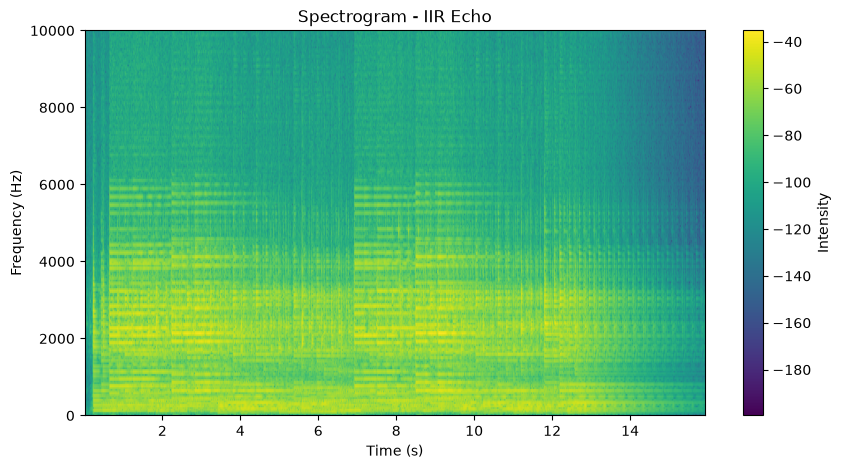

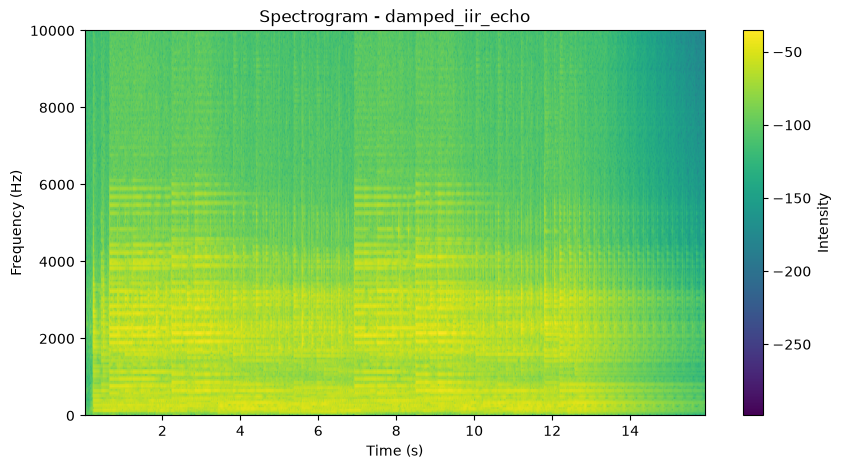

In [7]:
#3 vẽ phổ iir_echo và damped_iir_echo

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.specgram(
    y1,
    Fs=fs,
    NFFT=1024,
    noverlap=512
)

plt.title("Spectrogram - IIR Echo")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, 10000)
plt.colorbar(label="Intensity")
plt.show()


plt.figure(figsize=(10, 5))
plt.specgram(
    y2,
    Fs=fs,
    NFFT=1024,
    noverlap=512
)

plt.title("Spectrogram - damped_iir_echo")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, 10000)
plt.colorbar(label="Intensity")
plt.show()
